# 06 · Profiling and personas: persona deck and segment profile report

**Phase 4 deliverables:** the **persona deck** (PowerPoint) and the **segment profile report** (Word), plus the comparison charts.

Everything is read from the Week 3 views, for the segmentation the dashboard is using (`clean.segment_in_use`):

| View | SQL file |
|---|---|
| `segment_profile`, `segment_index`, `segment_channels`, `segment_stamp_duty`, `segment_browsing_hours` | `week3/10_segment_profiles.sql` |
| `segment_tiers`, `segment_actions`, `segment_demand`, `window_shoppers` | `week3/11_tiers_routing_demand.sql` |

Run it **after** switching to seg-v1.0 (file 9 STEP 1-3) and re-running files 10-14, so the personas describe the DS segments. It also runs on placeholder-A (the deck then says so).

**Gate:** persona cards signed off by the heads of sales, lettings and marketing (sign-off slide and table included).
**Outputs** (folder `reports/06_personas/`): `Veltrix_persona_deck.pptx`, `Veltrix_segment_profile_report.docx`, `persona_cards.xlsx`, charts.

In [1]:
# First time only:  %pip install python-pptx python-docx openpyxl sqlalchemy psycopg2-binary

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
import vx

vx.connect()
vx.style()
OUT = vx.out_dir("06_personas")
CH = OUT / "charts"
Q = vx.Q
MODEL = vx.segment_model()
display(Markdown(f"Segmentation in use: **{MODEL}**"))

Connected to database 'Veltrix' on localhost:5432 as postgres


Segmentation in use: **placeholder-A**

## 1. Facts per segment

In [3]:
prof = Q("SELECT * FROM clean.segment_profile ORDER BY segment_order")
act = Q("SELECT segment_name, priority_tier, routed_desk, agent_level, reply_target, best_first_contact, recommended_action FROM clean.segment_actions")
tiers = Q("SELECT segment_name, value_per_lead_index FROM clean.segment_tiers")
prof = prof.merge(act, on="segment_name", how="left").merge(tiers, on="segment_name", how="left")
SEGS = prof.segment_name.tolist()
COL = {s: vx.SERIES[i % 8] for i, s in enumerate(SEGS)}
ch = Q("SELECT segment_name, channel, pct_of_segment_leads, conversion_pct, channel_rank FROM clean.segment_channels WHERE channel_rank <= 3")
idx = Q("SELECT segment_name, metric_order, metric, segment_value, all_customers_value, index_vs_average FROM clean.segment_index")
dem = Q("""SELECT dimension, segment_name, value, property_events, deals FROM clean.segment_demand""")
topics = Q("""WITH t AS (SELECT d.segment_name, i.topic, count(*) n
                         FROM clean.clean_interactions i JOIN clean.clean_leads l USING (lead_id)
                         JOIN clean.dashboard_segments d USING (customer_id)
                         WHERE i.direction = 'Inbound' AND i.topic IS NOT NULL GROUP BY 1, 2),
                   s AS (SELECT segment_name, topic, n, n::float / sum(n) OVER (PARTITION BY segment_name) AS share FROM t),
                   a AS (SELECT topic, sum(n)::float / (SELECT sum(n) FROM t) AS share_all FROM t GROUP BY 1)
              SELECT s.segment_name, s.topic, s.share, round((100 * s.share / a.share_all)::numeric) AS topic_index
              FROM s JOIN a USING (topic) WHERE s.n >= 30""")
pay = Q("""SELECT d.segment_name, p.payment_type, count(*) n, avg(p.is_late_or_overdue) late
           FROM clean.clean_payments p JOIN clean.clean_transactions t USING (transaction_id)
           JOIN clean.dashboard_segments d ON d.customer_id = t.customer_id
           WHERE p.status <> 'Scheduled' GROUP BY 1, 2""")
stamp = Q("SELECT segment_name, leads_index FROM clean.segment_stamp_duty WHERE month = DATE '2025-03-01'") \
    if vx.exists("clean.segment_stamp_duty") else pd.DataFrame(columns=["segment_name", "leads_index"])
night = Q("""SELECT segment_name, sum(pct_of_segment_sessions) FILTER (WHERE session_hour_uk < 6) AS night_pct
             FROM clean.segment_browsing_hours GROUP BY 1""") if vx.exists("clean.segment_browsing_hours") else pd.DataFrame(columns=["segment_name", "night_pct"])
ws = Q("SELECT segment_name, count(*) AS window_shoppers FROM clean.window_shoppers GROUP BY 1") \
    if vx.exists("clean.window_shoppers") else pd.DataFrame(columns=["segment_name", "window_shoppers"])
prof = prof.merge(stamp, on="segment_name", how="left").merge(night, on="segment_name", how="left").merge(ws, on="segment_name", how="left")
prof[["segment_order", "segment_name", "customers", "pct_of_customers", "pct_of_deal_value", "conversion_pct", "late_payments_pct", "priority_tier"]]

,segment_order,segment_name,customers,pct_of_customers,pct_of_deal_value,conversion_pct,late_payments_pct,priority_tier
0,1,Home movers and downsizers,38011,37.8,42.5,17.2,2.9,P1
1,2,First-time buyers,21871,21.7,18.3,12.3,3.7,P2
2,3,UK renters,16818,16.7,1.4,24.9,12.3,P3
3,4,UK investors and landlords,11902,11.8,25.6,19.5,3.0,P1
4,5,Overseas buyers and tenants,9462,9.4,11.2,16.8,3.9,P1
5,6,Corporate and relocation tenants,2509,2.5,1.0,38.9,1.5,P3


In [4]:
def top_vals(dim, seg, col="property_events", n=3):
    d = dem[(dem.dimension == dim) & (dem.segment_name == seg)].dropna(subset=[col]).sort_values(col, ascending=False)
    tot = d[col].sum()
    return [(v, 100 * x / tot) for v, x in zip(d.value.head(n), d[col].head(n))] if tot else []

cards = []
for r in prof.itertuples():
    s = r.segment_name
    c = ch[ch.segment_name == s].sort_values("channel_rank")
    tp = topics[topics.segment_name == s].sort_values("topic_index", ascending=False)
    py = pay[pay.segment_name == s]
    ix = idx[idx.segment_name == s].set_index("metric")
    hi = ix.index_vs_average.astype(float).sort_values(ascending=False)
    rent_late = py.loc[py.payment_type == "Monthly rent", "late"]
    cards.append(dict(
        segment_name=s, tier=r.priority_tier, customers=int(r.customers), pct_customers=float(r.pct_of_customers),
        pct_value=float(r.pct_of_deal_value), conversion=float(r.conversion_pct), late=float(r.late_payments_pct),
        days_to_decide=r.median_days_to_decide, reply_h=float(r.median_first_reply_h) if pd.notna(r.median_first_reply_h) else np.nan,
        price=r.median_price_level_gbp, rent=r.median_rent_pcm, overseas=float(r.pct_overseas), device=r.main_device,
        channels=[(x.channel, float(x.pct_of_segment_leads), float(x.conversion_pct) if pd.notna(x.conversion_pct) else np.nan) for x in c.itertuples()],
        regions=top_vals("Region", s), types=top_vals("Property type", s), bands=top_vals("Price band", s),
        payment=top_vals("Payment structure", s, col="deals"),
        needs=[t for t in tp.topic.head(3)], needs_idx=[int(t) for t in tp.topic_index.head(3)],
        rent_late=float(100 * rent_late.iloc[0]) if len(rent_late) else np.nan,
        stamp=r.leads_index, night=r.night_pct, window_shoppers=r.window_shoppers,
        strengths=[(m, int(v)) for m, v in hi.head(3).items()], weaknesses=[(m, int(v)) for m, v in hi.tail(2).items()],
        desk=r.routed_desk, agent=r.agent_level, reply_target=r.reply_target, first_contact=r.best_first_contact,
        action=r.recommended_action, value_index=r.value_per_lead_index))
pd.DataFrame(cards).drop(columns=["channels", "regions", "types", "bands", "payment", "strengths", "weaknesses"]).to_excel(OUT / "persona_cards.xlsx", index=False)

def one_liner(c):
    price = f"budget around {vx.gbp(c['price'])}" if pd.notna(c["price"]) else (f"rent around £{c['rent']:,.0f} pcm" if pd.notna(c["rent"]) else "")
    reg = c["regions"][0][0] if c["regions"] else "-"
    typ = c["types"][0][0].lower() if c["types"] else "homes"
    return f"{c['pct_customers']:.0f}% of customers, {c['pct_value']:.0f}% of deal value; {price}; look most at {typ}s in {reg}."

for c in cards:
    display(Markdown(f"**{c['segment_name']}** ({c['tier']}): {one_liner(c)} Needs: {', '.join(c['needs'])}."))

**Home movers and downsizers** (P1): 38% of customers, 42% of deal value; budget around £395k; look most at flats in South East. Needs: School catchment, Retirement living, Chain and timescales.

**First-time buyers** (P2): 22% of customers, 18% of deal value; budget around £245k; look most at flats in North West. Needs: Shared ownership, Mortgage and finance, Stamp duty.

**UK renters** (P3): 17% of customers, 1% of deal value; rent around £1,400 pcm; look most at flats in London. Needs: Referencing, Tenancy terms, Viewing arrangements.

**UK investors and landlords** (P1): 12% of customers, 26% of deal value; budget around £195k; look most at flats in North West. Needs: Rental yield, Offer and negotiation, Stamp duty.

**Overseas buyers and tenants** (P1): 9% of customers, 11% of deal value; budget around £523k; look most at flats in London. Needs: Currency and transfers, Off-plan payment schedule, Visa and relocation.

**Corporate and relocation tenants** (P3): 2% of customers, 1% of deal value; rent around £2,800 pcm; look most at flats in London. Needs: Visa and relocation, Tenancy terms, Referencing.

## 2. Comparison charts

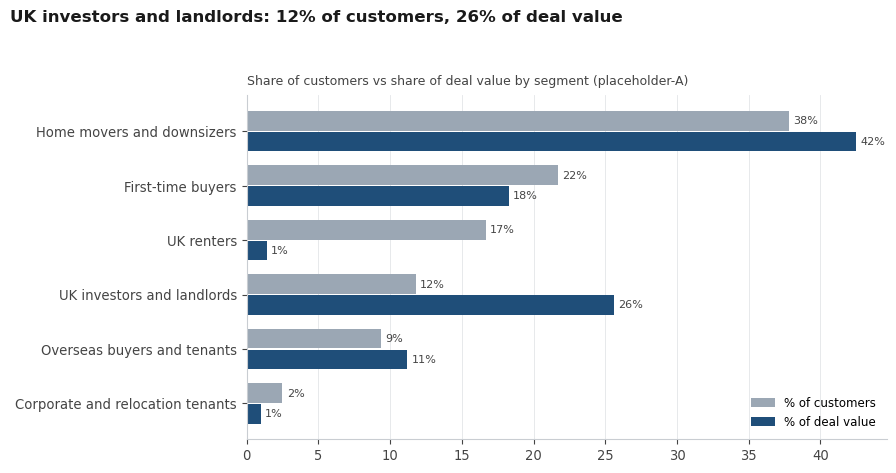

In [5]:
d = prof.sort_values("pct_of_customers")
fig, ax = plt.subplots(figsize=(9, 0.55 * len(d) + 1.4))
y = np.arange(len(d))
ax.barh(y + 0.19, d.pct_of_customers, 0.36, color=vx.GREY, label="% of customers")
b2 = ax.barh(y - 0.19, d.pct_of_deal_value, 0.36, color=vx.NAVY, label="% of deal value")
for i, (a, v) in enumerate(zip(d.pct_of_customers, d.pct_of_deal_value)):
    ax.annotate(f"{a:.0f}%", (a, i + 0.19), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=vx.INK2)
    ax.annotate(f"{v:.0f}%", (v, i - 0.19), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=vx.INK2)
ax.set_yticks(y, d.segment_name)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
lead = prof.assign(r=prof.pct_of_deal_value / prof.pct_of_customers).sort_values("r").iloc[-1]
p_size = vx.finish(fig, ax, f"{lead.segment_name}: {lead.pct_of_customers:.0f}% of customers, {lead.pct_of_deal_value:.0f}% of deal value",
                   f"Share of customers vs share of deal value by segment ({MODEL})", CH / "01_size_vs_value.png")

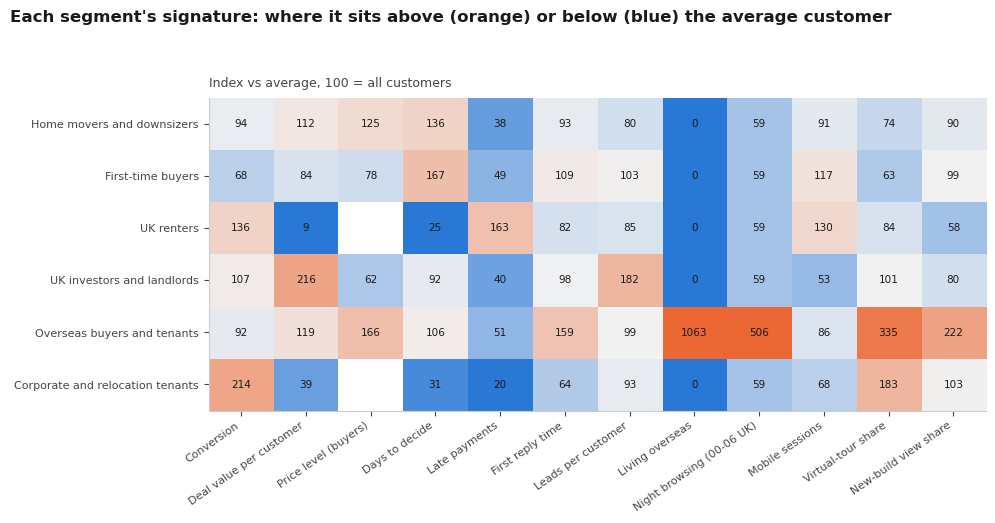

In [6]:
H = idx.pivot(index="segment_name", columns="metric", values="index_vs_average").astype(float)
order_m = idx.drop_duplicates("metric").sort_values("metric_order").metric
H = H.reindex(index=SEGS, columns=[m for m in order_m if m in H.columns])
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#F2F2F2", "#eb6834"])
fig, ax = plt.subplots(figsize=(10, 0.5 * len(H) + 2.2))
im = ax.imshow(np.log2(H.clip(lower=10) / 100), cmap=cmap, vmin=-2, vmax=2, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color=vx.INK)
ax.set_xticks(range(H.shape[1]), H.columns, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(H.shape[0]), H.index, fontsize=8)
ax.grid(False)
p_idx = vx.finish(fig, ax, "Each segment's signature: where it sits above (orange) or below (blue) the average customer",
                  "Index vs average, 100 = all customers", CH / "02_index_heatmap.png")

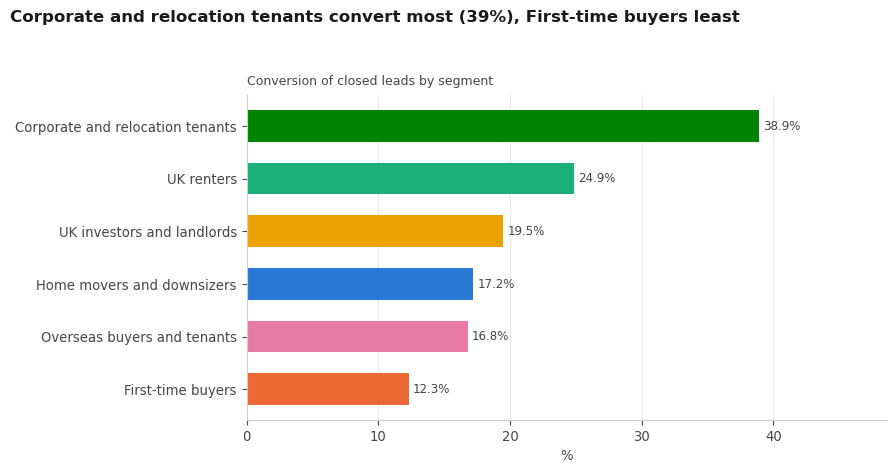

In [7]:
fig, ax = plt.subplots(figsize=(9, 0.55 * len(prof) + 1.4))
d = prof.sort_values("conversion_pct")
b = ax.barh(d.segment_name, d.conversion_pct, color=[COL[s] for s in d.segment_name], height=0.6)
vx.barh_labels(ax, b, "{:.1f}%")
ax.set_xlim(0, d.conversion_pct.max() * 1.25)
ax.grid(axis="y", visible=False)
p_conv = vx.finish(fig, ax, f"{d.iloc[-1].segment_name} convert most ({d.iloc[-1].conversion_pct:.0f}%), {d.iloc[0].segment_name} least",
                   "Conversion of closed leads by segment", CH / "03_conversion.png", xlabel="%")

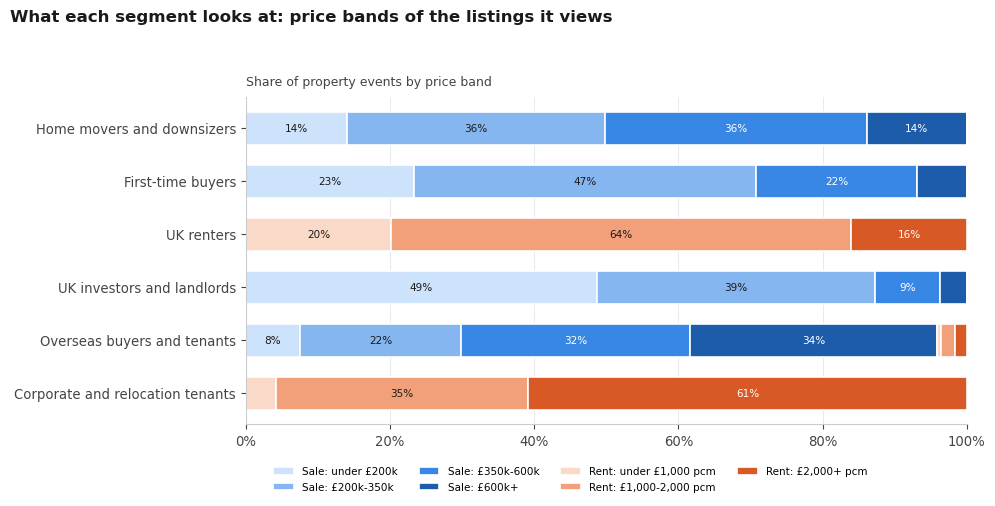

In [8]:
dd = dem[dem.dimension == "Price band"].dropna(subset=["property_events"])
dd = dd.assign(share=dd.property_events / dd.groupby("segment_name").property_events.transform("sum")).pivot(index="segment_name", columns="value", values="share").fillna(0)
dd = dd.reindex(index=SEGS[::-1])
bands = [b for b in ["Sale: under £200k", "Sale: £200k-350k", "Sale: £350k-600k", "Sale: £600k+", "Rent: under £1,000 pcm", "Rent: £1,000-2,000 pcm", "Rent: £2,000+ pcm"] if b in dd.columns]
pal = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#fbd9c8", "#f2a07a", "#d95926"]
fig, ax = plt.subplots(figsize=(10, 0.55 * len(dd) + 1.8))
left = np.zeros(len(dd))
for bnd, colr in zip(bands, pal):
    ax.barh(dd.index, dd[bnd], left=left, color=colr, label=bnd, height=0.62, edgecolor="white", linewidth=1.2)
    for i, (l, v) in enumerate(zip(left, dd[bnd])):
        if v > 0.07:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white" if colr in ("#3987e5", "#1c5cab", "#d95926") else vx.INK)
    left += dd[bnd].values
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncol=4, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.45, -0.1))
ax.grid(axis="y", visible=False)
p_band = vx.finish(fig, ax, "What each segment looks at: price bands of the listings it views", "Share of property events by price band",
                   CH / "04_price_bands.png")

## 3. The persona deck (PowerPoint)

In [9]:
from pptx import Presentation
from pptx.util import Inches, Pt, Emu
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN, MSO_ANCHOR
from pptx.enum.shapes import MSO_SHAPE
from pptx.chart.data import CategoryChartData
from pptx.enum.chart import XL_CHART_TYPE, XL_LEGEND_POSITION, XL_LABEL_POSITION

RGB = lambda h: RGBColor.from_string(h.lstrip("#").upper())
NAVY, ORANGE, INK, MUTED, TINT, WHITE = RGB("1F4E79"), RGB("E8702A"), RGB("1A1A1A"), RGB("5A5A5A"), RGB("EEF3F8"), RGB("FFFFFF")
TIER_COL = {"P1": RGB("E8702A"), "P2": RGB("1F4E79"), "P3": RGB("7F8C99")}
prs = Presentation()
prs.slide_width, prs.slide_height = Inches(13.333), Inches(7.5)
BLANK = prs.slide_layouts[6]

def tb(slide, x, y, w, h, text="", size=14, bold=False, color=INK, align=PP_ALIGN.LEFT, anchor=MSO_ANCHOR.TOP, font="Calibri"):
    box = slide.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h))
    tf = box.text_frame
    tf.word_wrap = True
    tf.vertical_anchor = anchor
    tf.margin_left = tf.margin_right = Inches(0.05)
    tf.margin_top = tf.margin_bottom = Inches(0.03)
    lines = text if isinstance(text, list) else [text]
    for i, ln in enumerate(lines):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.alignment = align
        parts = ln if isinstance(ln, list) else [(ln, bold)]
        for t, b in parts:
            r = p.add_run()
            r.text = t
            r.font.size, r.font.bold, r.font.color.rgb, r.font.name = Pt(size), b, color, font
    return box

def rect(slide, x, y, w, h, fill, shape=MSO_SHAPE.ROUNDED_RECTANGLE, radius=0.06):
    s = slide.shapes.add_shape(shape, Inches(x), Inches(y), Inches(w), Inches(h))
    s.fill.solid()
    s.fill.fore_color.rgb = fill
    s.line.fill.background()
    s.shadow.inherit = False
    if shape == MSO_SHAPE.ROUNDED_RECTANGLE:
        s.adjustments[0] = radius
    return s

def title(slide, text, sub=None):
    tb(slide, 0.6, 0.4, 12.1, 0.8, text, size=30, bold=True, color=NAVY)
    if sub:
        tb(slide, 0.6, 1.12, 12.1, 0.45, sub, size=14, color=MUTED)

def footer(slide, n):
    tb(slide, 0.6, 7.0, 9, 0.3, f"Veltrix segmentation · persona deck · {MODEL} · data to 30 Sep 2026", size=10, color=MUTED)
    tb(slide, 11.9, 7.0, 0.8, 0.3, str(n), size=10, color=MUTED, align=PP_ALIGN.RIGHT)

def stat(slide, x, y, w, value, label, color=NAVY, size=30):
    tb(slide, x, y, w, 0.6, value, size=size, bold=True, color=color)
    tb(slide, x, y + 0.6, w, 0.5, label, size=11, color=MUTED)

n = 0
# --- Title slide (dark)
s = prs.slides.add_slide(BLANK); n += 1
bg = rect(s, 0, 0, 13.333, 7.5, NAVY, shape=MSO_SHAPE.RECTANGLE)
tb(s, 0.8, 2.2, 11.5, 1.2, "Who buys and rents from Veltrix", size=44, bold=True, color=WHITE)
tb(s, 0.8, 3.4, 11.5, 0.6, f"{len(cards)} customer segments and what to do with each", size=22, color=RGB("CADCFC"))
tb(s, 0.8, 5.6, 11.5, 0.9, [f"Persona deck · Phase 4 · segmentation {MODEL}", f"{prof.customers.sum():,} customers · data to 30 Sep 2026"],
   size=14, color=RGB("CADCFC"))

# --- Segments at a glance: native chart + headline
s = prs.slides.add_slide(BLANK); n += 1
title(s, "A few segments carry most of the value", f"Share of customers and share of deal value, {len(cards)} segments")
cd = CategoryChartData()
dg = prof.sort_values("pct_of_deal_value")
cd.categories = list(dg.segment_name)
cd.add_series("% of customers", [round(v, 1) for v in dg.pct_of_customers])
cd.add_series("% of deal value", [round(v, 1) for v in dg.pct_of_deal_value])
gf = s.shapes.add_chart(XL_CHART_TYPE.BAR_CLUSTERED, Inches(0.6), Inches(1.7), Inches(8.2), Inches(5.1), cd)
chrt = gf.chart
chrt.has_title = False
chrt.has_legend = True
chrt.legend.position = XL_LEGEND_POSITION.BOTTOM
chrt.legend.include_in_layout = False
chrt.legend.font.size = Pt(11)
for ser, colr in zip(chrt.series, [RGB("9BA7B4"), NAVY]):
    ser.format.fill.solid()
    ser.format.fill.fore_color.rgb = colr
    ser.data_labels.show_value = True
    ser.data_labels.number_format = '0"%"'
    ser.data_labels.number_format_is_linked = False
    ser.data_labels.font.size = Pt(10)
    ser.data_labels.position = XL_LABEL_POSITION.OUTSIDE_END
chrt.plots[0].gap_width = 60
chrt.category_axis.tick_labels.font.size = Pt(11)
chrt.value_axis.visible = False
chrt.value_axis.has_major_gridlines = False
big = prof.sort_values("pct_of_deal_value").iloc[-1]
rect(s, 9.2, 1.9, 3.5, 4.7, TINT)
tb(s, 9.45, 2.1, 3.0, 0.4, "Biggest share of value", size=12, color=MUTED)
tb(s, 9.45, 2.5, 3.0, 0.9, f"{big.pct_of_deal_value:.0f}%", size=44, bold=True, color=ORANGE)
tb(s, 9.45, 3.4, 3.0, 0.8, f"{big.segment_name}, from {big.pct_of_customers:.0f}% of customers", size=14, color=INK)
p1 = prof[prof.priority_tier == "P1"]
tb(s, 9.45, 4.5, 3.0, 0.4, "Priority 1 segments", size=12, color=MUTED)
tb(s, 9.45, 4.9, 3.0, 0.9, f"{p1.pct_of_deal_value.sum():.0f}%", size=44, bold=True, color=NAVY)
tb(s, 9.45, 5.8, 3.0, 0.7, f"of deal value from {len(p1)} segment{'s' if len(p1) != 1 else ''}, {p1.pct_of_customers.sum():.0f}% of customers", size=14)
footer(s, n)

# --- One slide per persona
for c in cards:
    s = prs.slides.add_slide(BLANK); n += 1
    tier_c = TIER_COL.get(c["tier"], NAVY)
    badge = rect(s, 0.6, 0.52, 0.75, 0.5, tier_c, radius=0.3)
    badge.text_frame.text = c["tier"] or "-"
    for p_ in badge.text_frame.paragraphs:
        p_.alignment = PP_ALIGN.CENTER
        for r_ in p_.runs:
            r_.font.size, r_.font.bold, r_.font.color.rgb, r_.font.name = Pt(16), True, WHITE, "Calibri"
    tb(s, 1.5, 0.4, 11.2, 0.8, c["segment_name"], size=32, bold=True, color=NAVY)
    tb(s, 0.6, 1.15, 12.1, 0.5, one_liner(c), size=14, color=MUTED)
    # stat row
    stats_ = [(f"{c['customers']:,}", f"customers ({c['pct_customers']:.0f}%)"), (f"{c['pct_value']:.0f}%", "of deal value"),
              (f"{c['conversion']:.0f}%", "conversion of closed leads"), (f"{c['late']:.1f}%", "payments late"),
              (f"{c['days_to_decide']:.0f} d" if pd.notna(c["days_to_decide"]) else "-", "median days to decide")]
    for i, (v, lab) in enumerate(stats_):
        rect(s, 0.6 + i * 2.45, 1.8, 2.25, 1.25, TINT)
        stat(s, 0.75 + i * 2.45, 1.88, 2.0, v, lab, color=ORANGE if i == 1 else NAVY, size=26)
    # three columns: how they arrive / what they want / what they need
    cols_ = [
        ("How they arrive", [f"{ch_} · {sh:.0f}% of leads" + (f", converts {cv:.0f}%" if pd.notna(cv) else "") for ch_, sh, cv in c["channels"]]
         + ([f"Browse mostly on {c['device'].lower()}"] if isinstance(c["device"], str) else [])
         + ([f"{c['night']:.0f}% of sessions 00:00-06:00 UK"] if pd.notna(c["night"]) and c["night"] >= 8 else [])),
        ("What they look for", [f"{v}: {sh:.0f}% of views" for v, sh in c["regions"][:2]] + [f"{v}: {sh:.0f}%" for v, sh in c["types"][:1]]
         + [f"{v}: {sh:.0f}%" for v, sh in c["bands"][:1]] + [f"Finance: {v} ({sh:.0f}% of deals)" for v, sh in c["payment"][:1]]),
        ("What they ask about", [f"{t} (index {i_})" for t, i_ in zip(c["needs"], c["needs_idx"])]
         + ([f"Rent paid late {c['rent_late']:.0f}% of the time"] if pd.notna(c["rent_late"]) else [])
         + ([f"March 2025 rush: index {c['stamp']:.0f}"] if pd.notna(c["stamp"]) else [])),
    ]
    for i, (hd, items) in enumerate(cols_):
        x = 0.6 + i * 4.1
        tb(s, x, 3.3, 3.8, 0.4, hd, size=16, bold=True, color=NAVY)
        tb(s, x, 3.75, 3.8, 2.0, [[("·  " + it, False)] for it in items[:5]], size=13, color=INK)
    # action box
    rect(s, 0.6, 5.85, 12.1, 0.95, RGB("FDF1E9"))
    tb(s, 0.8, 5.92, 11.7, 0.85, [[("What to do  ", True), (c["action"] or "", False)]], size=13, color=INK, anchor=MSO_ANCHOR.MIDDLE)
    footer(s, n)

# --- Comparison heatmap
s = prs.slides.add_slide(BLANK); n += 1
title(s, "Each segment has a clear signature", "Index vs the average customer (100); orange = above, blue = below")
s.shapes.add_picture(str(p_idx), Inches(1.4), Inches(1.7), height=Inches(5.15))
footer(s, n)

# --- Timing slide
if len(stamp):
    s = prs.slides.add_slide(BLANK); n += 1
    st = prof.dropna(subset=["leads_index"]).sort_values("leads_index", ascending=False)
    title(s, "Not every segment rushed before the stamp duty change", "Leads in March 2025 against each segment's normal month (100)")
    cd = CategoryChartData()
    cd.categories = list(st.segment_name[::-1])
    cd.add_series("March 2025 leads index", [float(v) for v in st.leads_index[::-1]])
    gf = s.shapes.add_chart(XL_CHART_TYPE.BAR_CLUSTERED, Inches(0.6), Inches(1.7), Inches(7.8), Inches(5.1), cd)
    chrt = gf.chart
    chrt.has_title = False
    chrt.has_legend = False
    ser = chrt.series[0]
    ser.format.fill.solid()
    ser.format.fill.fore_color.rgb = NAVY
    ser.data_labels.show_value = True
    ser.data_labels.font.size = Pt(11)
    ser.data_labels.position = XL_LABEL_POSITION.OUTSIDE_END
    chrt.plots[0].gap_width = 60
    chrt.category_axis.tick_labels.font.size = Pt(11)
    chrt.value_axis.visible = False
    chrt.value_axis.has_major_gridlines = False
    rect(s, 8.9, 1.9, 3.8, 4.7, TINT)
    tb(s, 9.15, 2.1, 3.3, 4.3, [[("Contact first next time", True)], [(f"{st.iloc[0].segment_name} ran at {st.iloc[0].leads_index:.0f} and "
         f"{st.iloc[1].segment_name} at {st.iloc[1].leads_index:.0f}: their enquiries jump when tax rules change.", False)], [("", False)],
         [("Less sensitive", True)], [(f"{st.iloc[-1].segment_name} stayed near {st.iloc[-1].leads_index:.0f}.", False)]], size=14)
    footer(s, n)

# --- Sign-off (dark)
s = prs.slides.add_slide(BLANK); n += 1
rect(s, 0, 0, 13.333, 7.5, NAVY, shape=MSO_SHAPE.RECTANGLE)
tb(s, 0.8, 0.6, 11.5, 0.8, "Sign-off: do these personas describe our customers?", size=32, bold=True, color=WHITE)
tb(s, 0.8, 1.45, 11.5, 0.5, "Gate for Phase 5: the heads of sales, lettings and marketing approve the persona cards", size=16, color=RGB("CADCFC"))
for i, role in enumerate(["Head of sales", "Head of lettings", "Head of marketing"]):
    x = 0.8 + i * 4.0
    rect(s, x, 2.6, 3.6, 2.6, RGB("2A5F8F"))
    tb(s, x + 0.25, 2.8, 3.1, 0.5, role, size=18, bold=True, color=WHITE)
    tb(s, x + 0.25, 3.5, 3.1, 1.6, ["Name:", "", "Approved / changes:", "", "Date:"], size=13, color=RGB("CADCFC"))
tb(s, 0.8, 5.7, 11.5, 1.0, ["Next: segment names and tiers go into the CRM, routing rules go live, and the first six-week test starts (Phase 5)."],
   size=15, color=WHITE)
prs.save(OUT / "Veltrix_persona_deck.pptx")
print("Saved reports/06_personas/Veltrix_persona_deck.pptx,", n, "slides")

Saved reports/06_personas/Veltrix_persona_deck.pptx, 11 slides


## 4. The segment profile report (Word)

In [10]:
r = vx.Report("Segment profile report", f"Phase 4 · Profiling and personas · segmentation {MODEL}",
              "Week 3 views (segment_profile, segment_index, segment_channels, segment_demand) · generated by notebooks/06_personas.ipynb")
r.h1("Summary")
r.kpis([(f"{len(cards)}", "segments"), (f"{prof.customers.sum():,}", "customers"),
        (f"{p1.pct_of_deal_value.sum():.0f}%", "of deal value in P1 segments"), (f"{big.pct_of_deal_value:.0f}%", f"from {big.segment_name}")])
r.p(f"This report profiles the {len(cards)} segments of {MODEL}: who they are, how they arrive, what they look for and buy, how they pay, "
    "what they ask agents about, and what Veltrix should do with each. Every number is computed in SQL and appears on the dashboard's "
    "Segment deep dive page. Index values compare a segment with the average customer (100).")
summ = prof[["segment_name", "priority_tier", "customers", "pct_of_customers", "pct_of_deal_value", "conversion_pct", "late_payments_pct", "routed_desk"]]
summ.columns = ["Segment", "Tier", "Customers", "% customers", "% deal value", "Conversion %", "Late %", "Routed to"]
r.table(summ, caption="The segments at a glance", font=8, widths_cm=[4.2, 1.1, 2, 1.8, 1.9, 2, 1.4, 3.6])
r.image(p_size, "Share of customers and of deal value")
r.image(p_idx, "Index vs average on 12 measures")
r.image(p_conv, "Conversion by segment")
r.image(p_band, "Price bands looked at")
for c in cards:
    r.page_break()
    r.h1(f"{c['segment_name']}  ·  {c['tier']}")
    r.p(one_liner(c), muted=True)
    r.kpis([(f"{c['customers']:,}", "customers"), (f"{c['pct_value']:.0f}%", "of deal value"), (f"{c['conversion']:.0f}%", "conversion"),
            (f"{c['late']:.1f}%", "payments late")])
    facts = [["Median days to decide", f"{c['days_to_decide']:.0f}" if pd.notna(c["days_to_decide"]) else "-"],
             ["Median budget / rent", vx.gbp(c["price"]) if pd.notna(c["price"]) else (f"£{c['rent']:,.0f} pcm" if pd.notna(c["rent"]) else "-")],
             ["Living overseas", f"{c['overseas']:.0f}%"], ["Main device", c["device"] or "-"],
             ["Sessions 00:00-06:00 UK", f"{c['night']:.0f}%" if pd.notna(c["night"]) else "-"],
             ["Median first reply today", f"{c['reply_h']:.1f} h" if pd.notna(c["reply_h"]) else "-"],
             ["March 2025 leads index (stamp duty)", f"{c['stamp']:.0f}" if pd.notna(c["stamp"]) else "-"],
             ["Window shoppers (no enquiry yet)", f"{int(c['window_shoppers']):,}" if pd.notna(c["window_shoppers"]) else "-"]]
    r.table(pd.DataFrame(facts, columns=["Fact", "Value"]), widths_cm=[8, 6])
    r.h3("How they arrive")
    r.bullets([f"**{ch_}**: {sh:.0f}% of the segment's leads" + (f", converting {cv:.0f}%" if pd.notna(cv) else "") for ch_, sh, cv in c["channels"]])
    r.h3("What they look for and buy")
    r.bullets([f"**Regions:** " + ", ".join(f"{v} ({sh:.0f}%)" for v, sh in c["regions"]),
               f"**Property types:** " + ", ".join(f"{v} ({sh:.0f}%)" for v, sh in c["types"]),
               f"**Price bands:** " + ", ".join(f"{v} ({sh:.0f}%)" for v, sh in c["bands"]),
               f"**How they pay (deals):** " + (", ".join(f"{v} ({sh:.0f}%)" for v, sh in c["payment"]) or "no deals yet")])
    r.h3("What they ask about (needs)")
    r.bullets([f"{t} (asked {i_ / 100:.1f}x as often as the average customer)" for t, i_ in zip(c["needs"], c["needs_idx"])]
              + ([f"Monthly rent paid late {c['rent_late']:.0f}% of the time"] if pd.notna(c["rent_late"]) else []))
    r.h3("Stands out on")
    r.bullets([f"{m}: index {v}" for m, v in c["strengths"]] + [f"Lowest: {m} (index {v})" for m, v in c["weaknesses"]])
    r.callout(f"**Recommended action:** {c['action']}")
r.page_break()
r.h1("Sign-off")
r.p("Gate for Phase 5: the persona cards are approved by the heads of sales, lettings and marketing.")
r.table(pd.DataFrame([["Head of sales", "", "", ""], ["Head of lettings", "", "", ""], ["Head of marketing", "", "", ""]],
                     columns=["Role", "Name", "Approved / changes", "Date"]), widths_cm=[4, 4.5, 5.5, 3])
r.save(OUT / "Veltrix_segment_profile_report.docx")

Saved reports\06_personas\Veltrix_segment_profile_report.docx
